# Student Performance Prediction: A Classification Study

**Project type:** Supervised machine learning  
**Dataset:** UCI Student Performance — Mathematics course  
**Task:** Predict whether a student passes Mathematics based on demographic, social, and academic features.

## Research question
How well can K-Nearest Neighbors (KNN), Decision Tree, Support Vector Machine (SVM), and Artificial Neural Network (ANN) classify students as passing or failing?

## Target definition
The original final grade is `G3` (0–20). This project defines:
- `Pass = 1` when `G3 >= 10`
- `Pass = 0` when `G3 < 10`

**Important interpretation note:** `G1` and `G2` are included as predictors. They are grades from earlier periods, so this experiment predicts the final outcome using earlier academic results. It does not test prediction before any grades are available.

## Reproducibility
Download `student-mat.csv` from the [UCI Student Performance dataset page](https://archive.ics.uci.edu/dataset/320/student+performance) and place it in `data/raw/`. Then run the notebook from top to bottom.

## 1. Imports and configuration

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 2. Load and inspect the data

In [10]:
pd.read_csv("data/raw/student-mat.csv", sep=";")
print(f"Dataset shape: {df.shape}")
display(df.head())
df.info()

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [11]:
print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

print(f"Duplicate rows: {df.duplicated().sum()}")
display(df["G3"].describe())

Missing values per column:


school     0
sex        0
age        0
address    0
famsize    0
Pstatus    0
Medu       0
Fedu       0
Mjob       0
Fjob       0
dtype: int64

Duplicate rows: 0


count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

## 3. Define the classification target

A grade of 10/20 or higher is treated as a pass for this project. This threshold is a project assumption based on the dataset's grading context.

,Count,Proportion
Fail (0),130,0.329114
Pass (1),265,0.670886


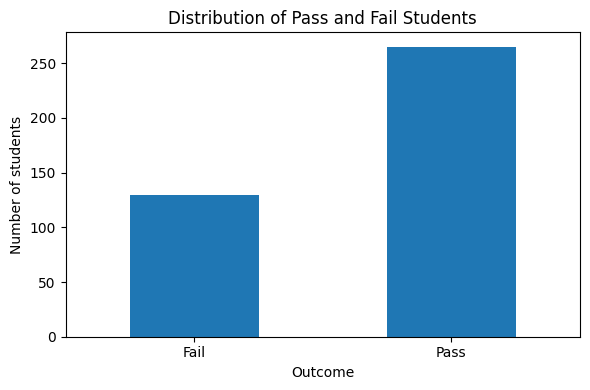

In [12]:
df["Pass"] = (df["G3"] >= 10).astype(int)

class_counts = df["Pass"].value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    "Count": class_counts,
    "Proportion": df["Pass"].value_counts(normalize=True).reindex([0, 1], fill_value=0)
})
class_summary.index = ["Fail (0)", "Pass (1)"]
display(class_summary)

ax = class_counts.rename(index={0: "Fail", 1: "Pass"}).plot(
    kind="bar", figsize=(6, 4), title="Distribution of Pass and Fail Students"
)
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Exploratory data analysis

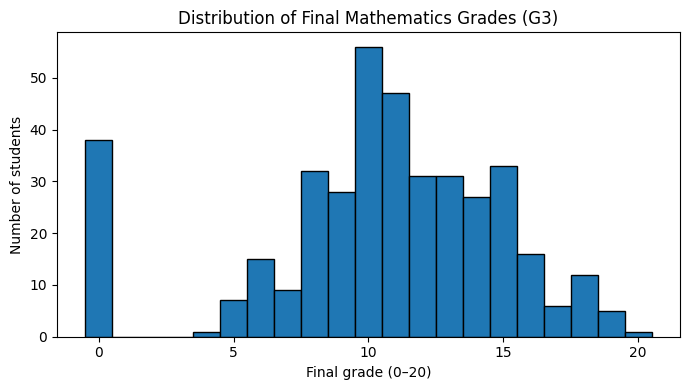

In [13]:
# Final-grade distribution
plt.figure(figsize=(7, 4))
plt.hist(df["G3"], bins=np.arange(-0.5, 21.5, 1), edgecolor="black")
plt.title("Distribution of Final Mathematics Grades (G3)")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

In [14]:
# Pass rates by selected variables
pass_by_studytime = df.groupby("studytime")["Pass"].mean()
pass_by_failures = df.groupby("failures")["Pass"].mean()

print("Pass rate by weekly study-time category:")
display(pass_by_studytime.rename("Pass rate").to_frame())

print("Pass rate by number of previous failures:")
display(pass_by_failures.rename("Pass rate").to_frame())

Pass rate by weekly study-time category:


,Pass rate
studytime,
1,0.647619
2,0.646465
3,0.753846
4,0.740741


Pass rate by number of previous failures:


,Pass rate
failures,
0,0.750000
1,0.480000
2,0.176471
3,0.250000


In [15]:
for column in ["internet", "higher", "schoolsup", "sex"]:
    print(f"Pass rate by {column}:")
    display(df.groupby(column, observed=False)["Pass"].mean().rename("Pass rate").to_frame())


Pass rate by internet:


,Pass rate
internet,
no,0.606061
yes,0.683891


Pass rate by higher:


,Pass rate
higher,
no,0.350
yes,0.688


Pass rate by schoolsup:


,Pass rate
schoolsup,
no,0.688953
yes,0.549020


Pass rate by sex:


,Pass rate
sex,
F,0.639423
M,0.705882


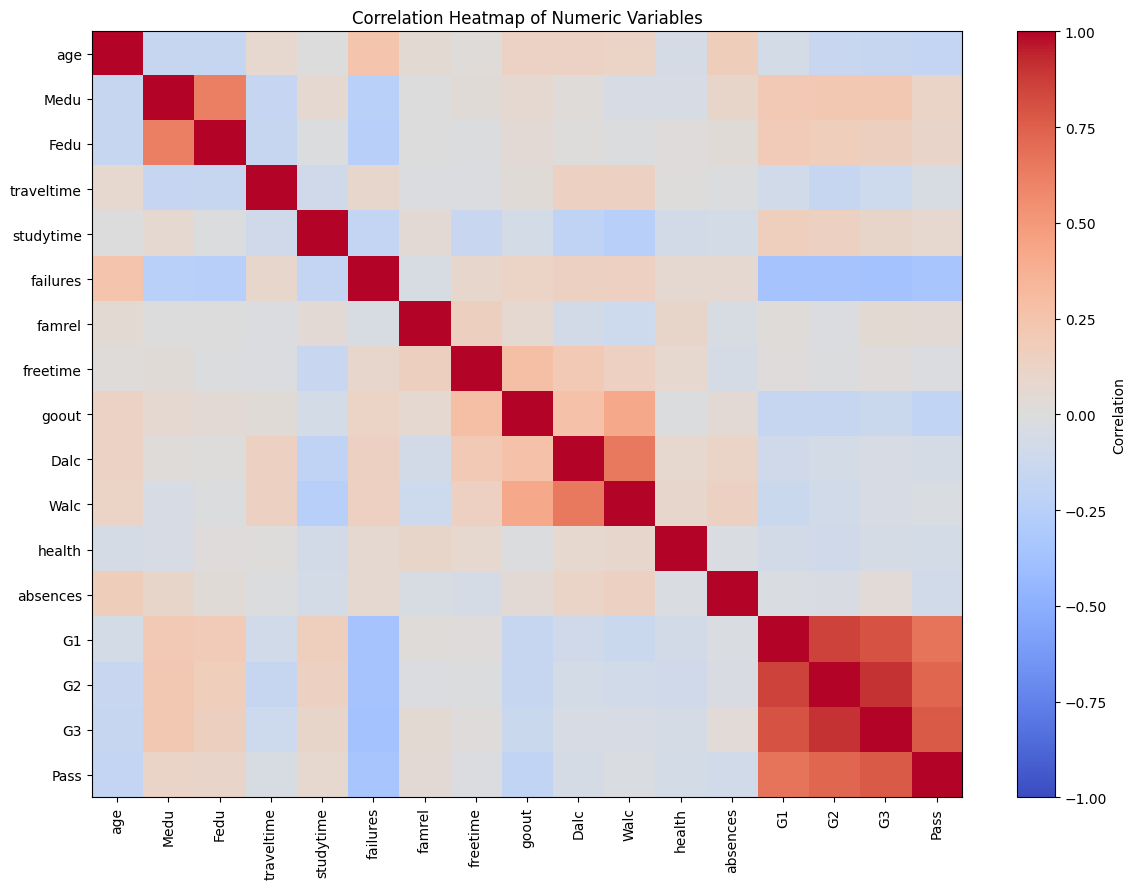

In [16]:
# Numeric-variable correlation heatmap (descriptive, not causal)
corr = df.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(corr, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

## 5. Prepare features and split the data

`G3` is removed because it is used to construct the target; retaining it would directly reveal the answer. Categorical predictors are one-hot encoded. The data is split into 80% training and 20% testing data using stratification to preserve the approximate pass/fail proportions.

Scaling is placed inside each model pipeline. This ensures that during cross-validation, the scaler is fitted only on each fold's training portion rather than on the entire training set.

In [17]:
# Keep the target separate and remove the original final grade.
X_raw = df.drop(columns=["G3", "Pass"])
y = df["Pass"]

# One-hot encode categorical variables.
X = pd.get_dummies(X_raw, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: "Fail", 1: "Pass"}))
print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename(index={0: "Fail", 1: "Pass"}))

Training set: (316, 41)
Testing set: (79, 41)

Training class proportions:


Pass
Fail    0.329114
Pass    0.670886
Name: proportion, dtype: float64


Testing class proportions:


Pass
Fail    0.329114
Pass    0.670886
Name: proportion, dtype: float64

## 6. Define and train the four classifiers

In [18]:
# Each pipeline keeps scaling within the cross-validation folds.
models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC())
    ]),
    "ANN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(50,),
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ])
}

In [19]:
results = []
confusion_matrices = {}
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    fitted_models[name] = model

    scores = {
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "CV Accuracy (2-fold)": cross_val_score(
            model, X_train, y_train, cv=2, scoring="accuracy"
        ).mean()
    }
    results.append(scores)
    confusion_matrices[name] = confusion_matrix(y_test, y_pred, labels=[0, 1])

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
display(results_df.round(4))

,Algorithm,Accuracy,Precision,Recall,F1 Score,CV Accuracy (2-fold)
1,Decision Tree,0.8481,0.9556,0.8113,0.8776,0.8576
3,ANN,0.8228,0.8545,0.8868,0.8704,0.8101
2,SVM,0.8101,0.8519,0.8679,0.8598,0.8165
0,KNN,0.6962,0.7231,0.8868,0.7966,0.7215


## 7. Evaluate model performance

Precision, recall, and F1-score are reported alongside accuracy because the pass and fail classes are not evenly represented. The positive class is `Pass = 1`, so recall measures the proportion of actual passing students correctly identified as passing. Review the confusion matrices as well as the summary metrics.


KNN
              precision    recall  f1-score   support

        Fail       0.57      0.31      0.40        26
        Pass       0.72      0.89      0.80        53

    accuracy                           0.70        79
   macro avg       0.65      0.60      0.60        79
weighted avg       0.67      0.70      0.67        79



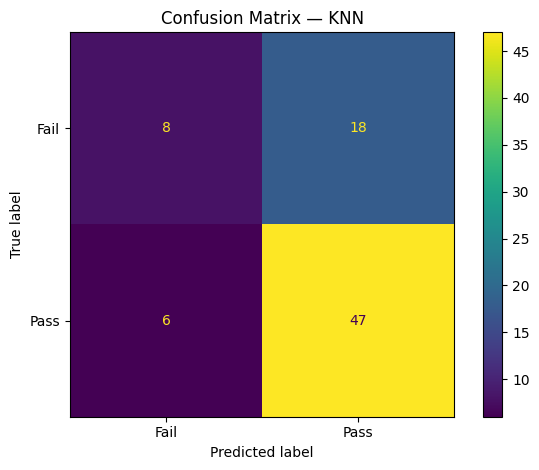


Decision Tree
              precision    recall  f1-score   support

        Fail       0.71      0.92      0.80        26
        Pass       0.96      0.81      0.88        53

    accuracy                           0.85        79
   macro avg       0.83      0.87      0.84        79
weighted avg       0.87      0.85      0.85        79



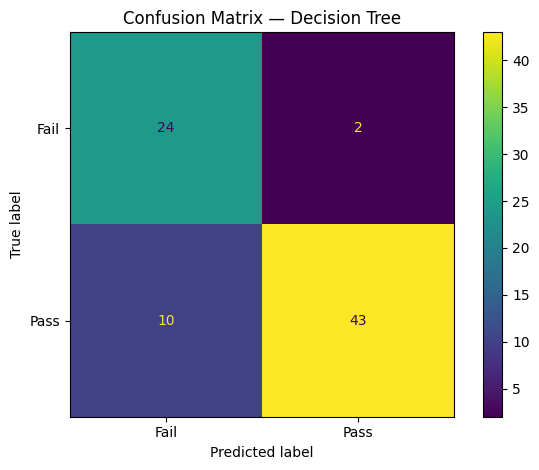


SVM
              precision    recall  f1-score   support

        Fail       0.72      0.69      0.71        26
        Pass       0.85      0.87      0.86        53

    accuracy                           0.81        79
   macro avg       0.79      0.78      0.78        79
weighted avg       0.81      0.81      0.81        79



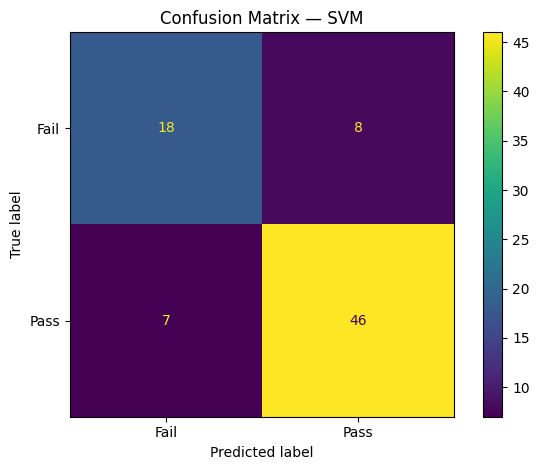


ANN
              precision    recall  f1-score   support

        Fail       0.75      0.69      0.72        26
        Pass       0.85      0.89      0.87        53

    accuracy                           0.82        79
   macro avg       0.80      0.79      0.80        79
weighted avg       0.82      0.82      0.82        79



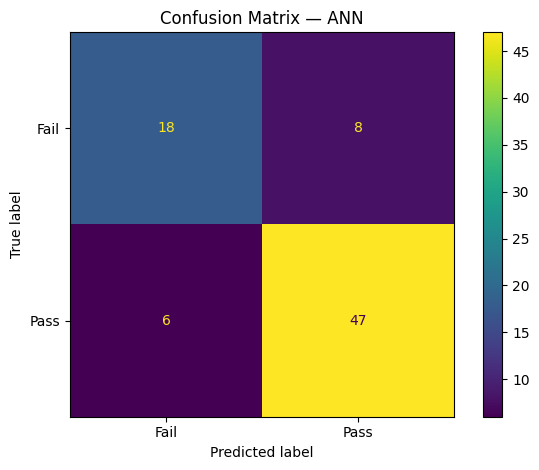

In [20]:
for name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    print(f"\n{name}")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Fail", "Pass"],
        zero_division=0
    ))

    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrices[name],
        display_labels=["Fail", "Pass"]
    ).plot(values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

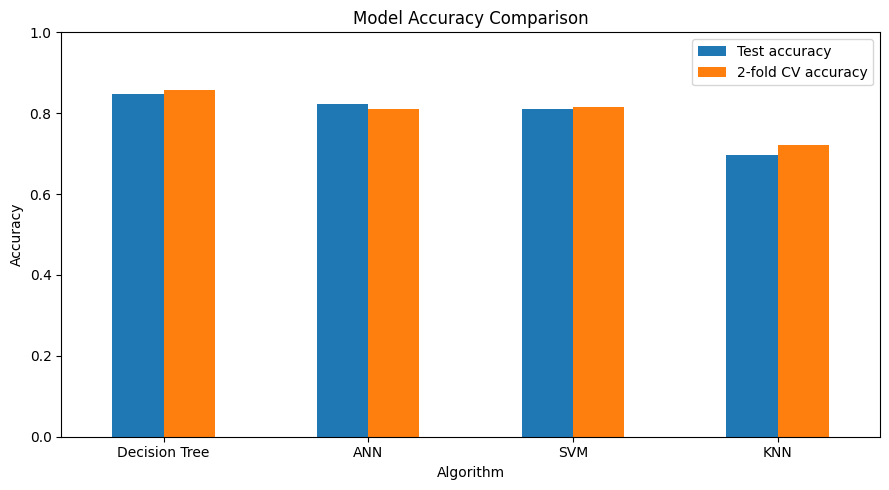

In [21]:
# Compare test-set accuracy and cross-validation accuracy
plot_df = results_df.set_index("Algorithm")[["Accuracy", "CV Accuracy (2-fold)"]]
ax = plot_df.plot(kind="bar", figsize=(9, 5), ylim=(0, 1))
ax.set_title("Model Accuracy Comparison")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Algorithm")
plt.xticks(rotation=0)
plt.legend(["Test accuracy", "2-fold CV accuracy"])
plt.tight_layout()
plt.show()

## 8. Decision Tree feature importance

Feature importance indicates which variables the fitted tree used most for its splits. It does **not** establish causation. When predictors are correlated or contain overlapping information, importance can be concentrated in one feature.

,Feature,Importance
0,G2,0.767129
1,Fjob_other,0.046438
2,traveltime,0.038671
3,Walc,0.033818
4,health,0.029063
5,famsize_LE3,0.017199
6,age,0.011964
7,G1,0.011825
8,schoolsup_yes,0.010749
9,absences,0.010749


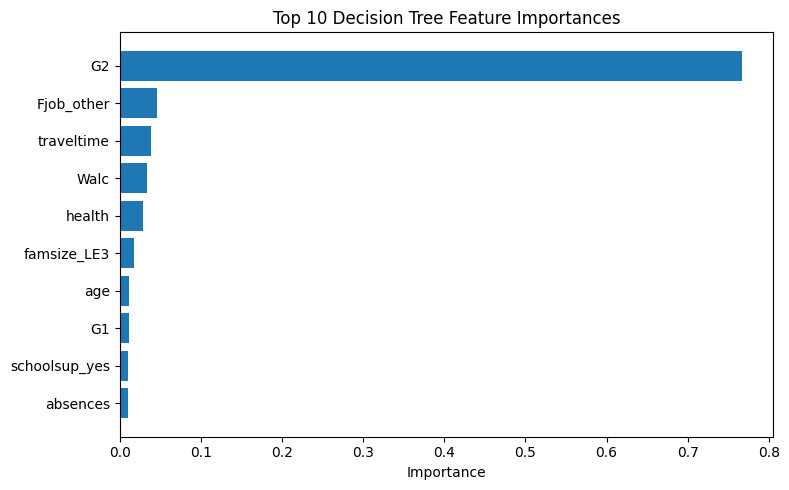

In [22]:
tree = fitted_models["Decision Tree"].named_steps["classifier"]

feature_importance = (
    pd.DataFrame({
        "Feature": X.columns,
        "Importance": tree.feature_importances_
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.head(10))

top_features = feature_importance.head(10).sort_values("Importance")
plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Decision Tree Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 9. Findings, limitations, and next steps

When reporting the results, use the metrics produced by the notebook after running all cells. Do not assume a model is best based on accuracy alone.

### Limitations
- The dataset contains 395 Mathematics-course records from two Portuguese schools, so findings may not generalize to other populations.
- The pass threshold (`G3 >= 10`) is a project definition and should be stated explicitly.
- `G1` and `G2` are included, so the model uses earlier grades to predict the final grade. A separate experiment excluding `G1` and `G2` would answer a different, potentially more useful early-prediction question.
- The dataset is observational. Associations and feature importances do not show that a factor causes academic success or failure.
- Two-fold cross-validation is used here to match the course assignment; more folds or repeated evaluation may give a more stable estimate in a larger study.

### Ethical note
This is an educational exercise, not a validated system for making real decisions about students. Predictions should not be used to deny opportunities or replace educators' judgment.